### Plain Recursion vs Memoized Recursion


###### Part 1


In [1]:
import sys


def recursive_fibonacci(n, counter):
    counter["recursive_fib"] += 1
    if n == 0 or n == 1:
        value = n
    else:
        value = recursive_fibonacci(n - 1, counter) + recursive_fibonacci(n - 2, counter)
    return value


def memoized_fibonacci(n, fibtable, counter):
    counter["memoized_fib"] += 1
    if n in fibtable:
        return fibtable[n]
    elif n == 0 or n == 1:
        value = n
    else:
        value = memoized_fibonacci(n - 1, fibtable, counter) + memoized_fibonacci(n - 2, fibtable, counter)

    fibtable[n] = value
    return value

In [10]:
fibtable = {0: 0, 1: 1}

for n in range(20):
    print("=" * 30, "\nN = ", n)
    counter = {"recursive_fib": 0, "memoized_fib": 0}
    print("Plain Recursion: ", recursive_fibonacci(n, counter))
    print("Memoized Recursion: ", memoized_fibonacci(n, fibtable, counter))


N =  0
Plain Recursion:  0
Memoized Recursion:  0
N =  1
Plain Recursion:  1
Memoized Recursion:  1
N =  2
Plain Recursion:  1
Memoized Recursion:  1
N =  3
Plain Recursion:  2
Memoized Recursion:  2
N =  4
Plain Recursion:  3
Memoized Recursion:  3
N =  5
Plain Recursion:  5
Memoized Recursion:  5
N =  6
Plain Recursion:  8
Memoized Recursion:  8
N =  7
Plain Recursion:  13
Memoized Recursion:  13
N =  8
Plain Recursion:  21
Memoized Recursion:  21
N =  9
Plain Recursion:  34
Memoized Recursion:  34
N =  10
Plain Recursion:  55
Memoized Recursion:  55
N =  11
Plain Recursion:  89
Memoized Recursion:  89
N =  12
Plain Recursion:  144
Memoized Recursion:  144
N =  13
Plain Recursion:  233
Memoized Recursion:  233
N =  14
Plain Recursion:  377
Memoized Recursion:  377
N =  15
Plain Recursion:  610
Memoized Recursion:  610
N =  16
Plain Recursion:  987
Memoized Recursion:  987
N =  17
Plain Recursion:  1597
Memoized Recursion:  1597
N =  18
Plain Recursion:  2584
Memoized Recursion:  2584

##### Part 2

In [19]:
import time
from typing import TypedDict, List
from matplotlib import pyplot as plt

class ResultTuple(TypedDict):
    n: int
    calls: int
    time: float

In [12]:
# Plain Recursion
recur_results: list[ResultTuple] = []
for n in range(5, 35, 5):
    print("="*20,"\nN = ", n)
    start = time.perf_counter()
    counter = {"recursive_fib": 0, "memoized_fib": 0}
    print("n_fib: ", recursive_fibonacci(n, counter))
    end = time.perf_counter()
    _time = float(end - start)
    result = ResultTuple(n=n, calls=counter["recursive_fib"], time=_time)
    recur_results.append(result)
    if _time > 60: break
print("="*20,"LARGEST n ACHIEVED: ", recur_results[-1]['n'])

N =  5
n_fib:  5
N =  10
n_fib:  55
N =  15
n_fib:  610
N =  20
n_fib:  6765
N =  25
n_fib:  75025
N =  30
n_fib:  832040
==================== LARGEST n ACHIEVED:  30


In [29]:
import sys
# change python default settings for recusion depth
print("Current Depth: ", sys.getrecursionlimit())

sys.setrecursionlimit(10_000)

print("New Depth: ", sys.getrecursionlimit())

Current Depth:  10000
New Depth:  10000


In [30]:
# Memoized Recursion
mem_results: list[ResultTuple] = []

def format_large_number(num, max_chars=15):
    if len(str(num)) > max_chars:
        return f"{num:.10e}"
    return num

for n in [10, 50, 100, 200, 500, 1000]:
    print("="*40,"\nN = ", n)
    fibtable = {0: 0, 1: 1}
    counter = {"recursive_fib": 0, "memoized_fib": 0}
    start = time.perf_counter()
    print("n_fib: ", format_large_number(memoized_fibonacci(n, fibtable, counter)))
    end = time.perf_counter()
    _time = float(end - start)
    result = ResultTuple(n=n, calls=counter["memoized_fib"], time=_time)
    mem_results.append(result)

N =  10
n_fib:  55
N =  50
n_fib:  12586269025
N =  100
n_fib:  3.5422484818e+20
N =  200
n_fib:  2.8057117299e+41
N =  500
n_fib:  1.3942322456e+104
N =  1000
n_fib:  4.3466557687e+208


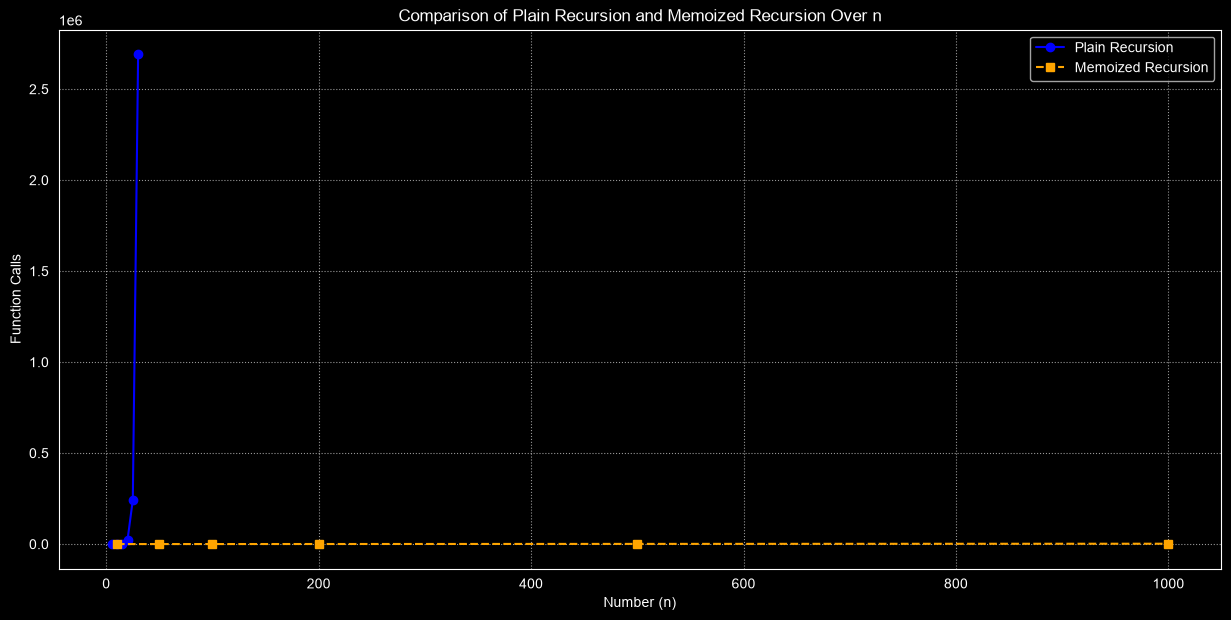

In [31]:
plt.figure(figsize=(15, 7))

plt.plot([item['n'] for item in recur_results], [item['calls'] for item in recur_results], label="Plain Recursion", color="blue", marker="o", linestyle="-")
plt.plot([item['n'] for item in mem_results], [item['calls'] for item in mem_results], label="Memoized Recursion", color="orange", marker="s", linestyle="--")

plt.xlabel("Number (n)")
plt.ylabel("Function Calls")
plt.title("Comparison of Plain Recursion and Memoized Recursion Over n")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)


plt.show()

In [32]:
# reset recursion limit
sys.setrecursionlimit(1000)